# Домашняя работа №1. Проверка валидности A/B-эксперимента

Сосновский Егор, М26-515

## Описание задания

Вы получили данные эксперимента. Вам нужно проверить корректность дизайна и данных, найти скрытые проблемы (специально добавленные в данные) и предложить пути их исправления. Задача требует написания Python-кода и аналитического вывода. Данные генерируются случайно, а проблемы нужно обнаружить с помощью расчётов.

В файле `experiment_data.csv` содержатся следующие колонки:

- `user_id` - идентификатор пользователя.
- `variant` - группа: control или test.
- `converted` - совершил ли целевое действие (1/0).
- `error_flag` - была ли ошибка при загрузке страницы (1/0). Это guardrail-метрика, по которой проверяют, не стало ли пользователю хуже.
- `pre_activity` - количество действий пользователя за неделю до эксперимента. В условии эта ковариата названа непрерывной.
- `date` - дата события. Для этой задачи её можно не использовать в расчётах.

По условию ожидается соотношение групп 50/50. Рандомизация должна быть независима от `pre_activity`. В генератор добавлены три нарушения: неверное соотношение групп, зависимость назначения от активности и рост частоты ошибок в test. Прямого влияния варианта на конверсию в генераторе нет.

К работе прилагается отдельный файл `experiment_data.csv`. Ноутбук читает его из своей рабочей папки. В Colab перед повторным запуском нужно загрузить этот CSV в рабочую среду. Все расчёты, таблицы и графики уже выполнены на этом файле и сохранены в ноутбуке.

Ноутбук и CSV размещаются на одной площадке. На образовательную платформу отправляется ссылка на работу, сами файлы к ответу не прикладываются.

## 1. Исходные данные и загрузка CSV

### Условие

Сгенерируйте файл `experiment_data.csv` по коду задания. Данные должны быть уникальными. Загрузите файл для дальнейшего анализа.

### Решение

отдельный файл `experiment_data.csv` содержит синтетические данные, полученные по генератору из задания. seed `382913` выбран один раз командой `np.random.randint(5000000, size=1)[0]`. в выборке 4617 пользователей. повторная генерация при анализе не выполняется.

параметры и порядок случайных вызовов сохранены. в исходнике после словаря `DataFrame` стояло `}]`, эта скобка исправлена на `})`. первая переменная `variant` позднее перезаписывается через `variant2`, поэтому итоговое распределение не обязано быть 40/60.

в комментарии исходника указано логнормальное распределение, но `exponential()` создаёт экспоненциальное. после `astype(int)` активность содержит целые числа. эти особенности учтены в анализе.

`pd.read_csv(data_path, parse_dates=['date'])` читает загруженный CSV и переводит столбец `date` в даты. относительный путь `experiment_data.csv` означает файл в рабочей папке ноутбука. если файл отсутствует, расчёт останавливается с сообщением о необходимости загрузки. CSV не создаётся и не перезаписывается.

`MY_SEED` ниже используется только для воспроизводимого подбора пользователей в бонусной части. основная выборка во всех расчётах берётся из CSV.

### Код

In [1]:
# numpy нужен для расчётов, pandas читает CSV и считает показатели по группам
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# критерии нужны для пропорции групп, активности и частоты ошибок
from scipy.stats import chisquare, mannwhitneyu, fisher_exact, binomtest
from IPython.display import display

ALPHA = 0.05
GROUPS = ['control', 'test']
COLORS = ['#245B8A', '#C05B22']
data_path = 'experiment_data.csv'
# seed относится к исходной выборке, здесь он нужен только для подбора в бонусе
MY_SEED = 382913

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 120,
})

# читаем отдельный файл, который загружен в рабочую среду ноутбука
try:
    df = pd.read_csv(data_path, parse_dates=['date'])
except FileNotFoundError:
    # отсутствие исходного файла нельзя подменять генерацией новой выборки
    raise FileNotFoundError(
        'Загрузите experiment_data.csv в рабочую папку ноутбука '
        'и повторно запустите ячейки. В Colab CSV нужно загрузить '
        'в рабочую среду этого ноутбука.'
    ) from None

### Проверка

In [2]:
# проверяем размер исходной выборки и отсутствие повторных пользователей
assert len(df) == 4617, 'Число пользователей отличается от исходного CSV этой работы.'
assert df.user_id.is_unique
print(f'Файл: {data_path}')
print(f'Пользователей: {len(df)}')
print(f'Столбцов: {len(df.columns)}')
print(f'Период: {df.date.min():%d.%m.%Y} - {df.date.max():%d.%m.%Y}')
display(df.head())

Файл: experiment_data.csv
Пользователей: 4617
Столбцов: 6
Период: 01.05.2026 - 14.05.2026


,user_id,variant,converted,error_flag,pre_activity,date
0,0,test,0,0.0,0,2026-05-04
1,1,control,0,0.0,2,2026-05-13
2,2,control,0,0.0,35,2026-05-11
3,3,test,0,0.0,10,2026-05-04
4,4,control,0,0.0,0,2026-05-13


из отдельного CSV прочитаны 4617 пользователей и 6 столбцов. даты находятся в пределах 1-14 мая 2026 года. все следующие расчёты используют эту загруженную таблицу.

## 2. Основные показатели и качество данных

### Условие

Загрузите `experiment_data.csv` и выведите базовую информацию: размеры групп, среднюю конверсию и частоту ошибок.

### Решение

в этой таблице одна строка соответствует одному пользователю. повторный `user_id` мог бы увеличить его вклад в расчёт, поэтому сначала проверяются дубли, пропуски, названия групп, значения 0/1 и допустимая активность.

`groupby('variant')` разделяет пользователей на control и test. для `converted` среднее равно числу конверсий, делённому на размер группы. например, в control это `121 / 2625`. частота ошибок считается тем же способом по `error_flag`.

разница конверсий `test - control` сначала получается в долях. умножение на 100 переводит её в процентные пункты. для относительной разницы нужно разделить её на конверсию control. эти два показателя нельзя подменять друг другом.

пользователи с ошибкой загрузки остаются в данных. если убрать их до расчёта, частота ошибок станет заниженной.

### Код

In [3]:
required_columns = {
    'user_id', 'variant', 'converted', 'error_flag', 'pre_activity', 'date'
}
if set(df.columns) != required_columns:
    raise ValueError('Набор столбцов не соответствует условию.')
if df.empty:
    raise ValueError('В файле нет пользователей.')

# неправильные значения нужно обнаружить до статистических тестов
quality_errors = []
if df.isna().any().any():
    quality_errors.append('Есть пропуски.')
if df.user_id.duplicated().any():
    quality_errors.append('Есть повторные user_id.')
if set(df.variant.unique()) != set(GROUPS):
    quality_errors.append('Должны присутствовать только группы control и test.')
for column in ['converted', 'error_flag']:
    if not df[column].isin([0, 1]).all():
        quality_errors.append(f'{column} должен содержать только 0 и 1.')
if not np.isfinite(df.pre_activity).all() or (df.pre_activity < 0).any():
    quality_errors.append('Активность должна быть конечной и неотрицательной.')
if not (df.pre_activity % 1 == 0).all():
    quality_errors.append('В этом генераторе активность должна быть целочисленной.')
if not df.date.between('2026-05-01', '2026-05-14').all():
    quality_errors.append('Есть даты вне периода генерации.')
if quality_errors:
    raise ValueError(' '.join(quality_errors))


# у бинарного признака среднее равно доле единиц
# size считает пользователей, sum считает конверсии и ошибки
summary = df.groupby('variant').agg(
    users=('user_id', 'size'),
    conversions=('converted', 'sum'),
    conversion_rate=('converted', 'mean'),
    errors=('error_flag', 'sum'),
    error_rate=('error_flag', 'mean'),
).reindex(GROUPS)
summary['errors'] = summary.errors.astype(int)
summary['share'] = summary.users / len(df)


# отдельные таблицы пригодятся для сравнения активности
control = df.loc[df.variant == 'control']
test = df.loc[df.variant == 'test']
# абсолютная разница считается в долях, относительная делится на control
conversion_diff = summary.loc['test', 'conversion_rate'] - summary.loc['control', 'conversion_rate']
conversion_lift = conversion_diff / summary.loc['control', 'conversion_rate']

### Проверка

In [4]:
print(f'Пропуски: {int(df.isna().sum().sum())}')
print(f'Повторные user_id: {int(df.user_id.duplicated().sum())}')

# меняем названия и формат только у таблицы для показа
summary_view = summary.rename(columns={
    'users': 'Пользователи',
    'conversions': 'Конверсии',
    'conversion_rate': 'Конверсия',
    'errors': 'Ошибки',
    'error_rate': 'Частота ошибок',
    'share': 'Доля группы',
})
for column in ['Конверсия', 'Частота ошибок', 'Доля группы']:
    summary_view[column] = summary_view[column].map('{:.2%}'.format)
display(summary_view)

print(f'Разница конверсий test - control: {100 * conversion_diff:.3f} п.п.')
print(f'Относительная разница: {100 * conversion_lift:.2f}%')

Пропуски: 0
Повторные user_id: 0


,Пользователи,Конверсии,Конверсия,Ошибки,Частота ошибок,Доля группы
variant,,,,,,
control,2625,121,4.61%,18,0.69%,56.86%
test,1992,105,5.27%,45,2.26%,43.14%


Разница конверсий test - control: 0.662 п.п.
Относительная разница: 14.35%


в control 2625 пользователей, в test 1992. конверсия составляет 4,61% и 5,27%, частота ошибок 0,69% и 2,26%. наблюдаемая разница конверсий равна 0,662 процентного пункта, или 14,35% относительно control. пока это только сравнение чисел, влияние варианта ещё не установлено.

## 3. Соотношение групп, SRM

### Условие

Проверьте SRM (Sample Ratio Mismatch), например, с помощью хи-квадрат теста. Ожидаемое соотношение 50/50. Если p-value < 0.05, выведите предупреждение «SRM обнаружен».

### Решение

SRM означает, что размеры групп расходятся с запланированной пропорцией сильнее, чем ожидается при случайном распределении. нулевая гипотеза здесь: каждый пользователь попадает в test с вероятностью 0,5.

`observed` содержит 2625 и 1992, а `expected` содержит по `4617 / 2 = 2308,5`. ожидаемое количество может быть дробным, это расчётное значение. `chisquare()` сравнивает эти два набора и возвращает статистику и p-value.

если p-value меньше `ALPHA = 0.05`, срабатывает предупреждение из условия. на графике пунктир показывает ожидаемый размер каждой группы.

### Код

In [5]:
# observed содержит реальные размеры control и test в этом порядке
observed = summary.users.to_numpy()
# при плане 50/50 на каждую группу приходится половина всех пользователей
expected = np.array([len(df) / 2, len(df) / 2])
# критерий сравнивает количества, поэтому передаём числа пользователей
srm_result = chisquare(f_obs=observed, f_exp=expected)
p_srm = float(srm_result.pvalue)

### Проверка

Фактически: control = 2625, test = 1992
Ожидалось: 2308.5 в каждой группе
Хи-квадрат: 86.786. p-value: 1.21e-20
SRM обнаружен


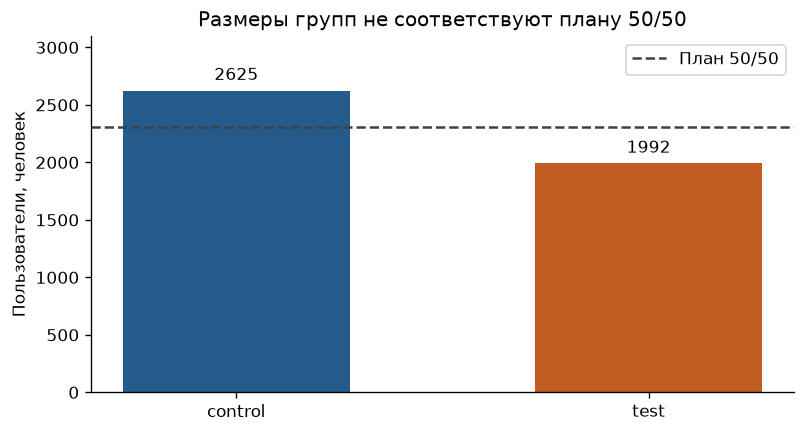

In [6]:
print(f'Фактически: control = {observed[0]}, test = {observed[1]}')
print(f'Ожидалось: {expected[0]:.1f} в каждой группе')
print(f'Хи-квадрат: {srm_result.statistic:.3f}. p-value: {p_srm:.3g}')
if p_srm < ALPHA:
    print('SRM обнаружен')
else:
    print('Значимого отклонения от 50/50 не обнаружено.')

fig, ax = plt.subplots(figsize=(6.6, 3.5), layout='constrained')
bars = ax.bar(GROUPS, observed, color=COLORS, width=0.55)
ax.axhline(expected[0], color='#414141', linestyle='--', label='План 50/50')
ax.bar_label(bars, padding=4)
ax.set_ylim(0, max(observed) * 1.18)
ax.set_ylabel('Пользователи, человек')
ax.set_title('Размеры групп не соответствуют плану 50/50')
ax.legend(loc='upper right')
plt.show()

p-value равен примерно 1,21 · 10⁻²⁰, поэтому план 50/50 не соблюдён. в test попало 43,14% пользователей. причина видна в генераторе: вероятность test зависит от активности и не равна 0,5. само неравенство размеров не всегда является ошибкой, но здесь оно противоречит заданному плану.

## 4. Баланс исходной активности

### Условие

Проверьте баланс ковариаты `pre_activity` между группами. Используйте t-test или U-тест, если распределение не нормальное. Если p-value < 0.05, выведите предупреждение «Дисбаланс по pre_activity: возможен confounder».

### Решение

`pre_activity` измерена до эксперимента. если группы уже отличались по этой активности, разницу конверсий нельзя сразу объяснить новым вариантом.

распределение активности скошено вправо: небольшие значения частые, большие редкие. здесь используется двусторонний U-тест Манна-Уитни. он сравнивает ранги значений двух групп. это не универсальная проверка равенства средних или медиан. `method='asymptotic'` учитывает повторяющиеся целые значения при расчёте p-value.

дополнительно считается SMD, стандартизованная разница средних. из среднего test вычитается среднее control, затем результат делится на корень из среднего двух выборочных дисперсий. так разница выражается в единицах разброса.

левая часть графика показывает распределения активности. правая показывает долю test для пяти интервалов активности. интервалы нужны только для графика, сам U-тест использует исходные значения.

### Код

In [7]:
# среднее и медиана описывают положение данных, std показывает разброс
activity_summary = df.groupby('variant').pre_activity.agg(
    ['mean', 'median', 'std', 'min', 'max']
).reindex(GROUPS)


# сравниваем все исходные значения, не объединяя их в интервалы
# asymptotic учитывает повторяющиеся значения через поправку на совпадения рангов
activity_result = mannwhitneyu(
    test.pre_activity,
    control.pre_activity,
    alternative='two-sided',
    method='asymptotic',
)
p_activity = float(activity_result.pvalue)
activity_diff = test.pre_activity.mean() - control.pre_activity.mean()
# SMD делит разницу средних на общий масштаб разброса двух групп
activity_scale = np.sqrt((test.pre_activity.var() + control.pre_activity.var()) / 2)
smd = activity_diff / activity_scale

### Проверка

,Среднее,Медиана,Стандартное отклонение,Минимум,Максимум
variant,,,,,
control,8.605,6.0,9.033,0,72
test,10.292,7.0,10.696,0,70


U-статистика: 2839206.0. p-value: 5.22e-07
Разница средних test - control: 1.686 действия
SMD: 0.170
Дисбаланс по pre_activity: возможен confounder


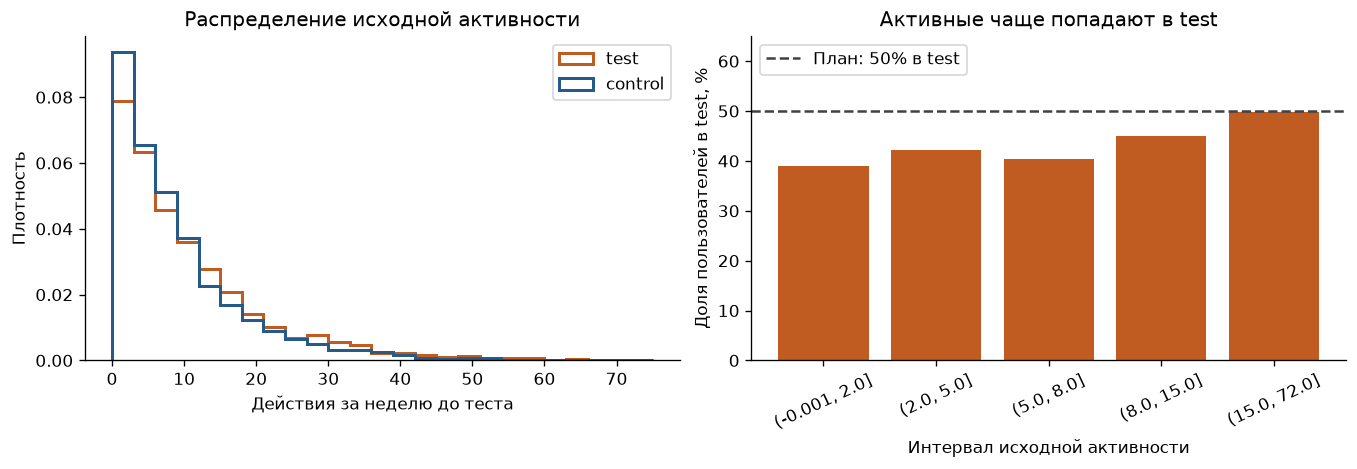

In [8]:
display(activity_summary.rename(columns={
    'mean': 'Среднее', 'median': 'Медиана', 'std': 'Стандартное отклонение',
    'min': 'Минимум', 'max': 'Максимум',
}).round(3))

print(f'U-статистика: {activity_result.statistic:.1f}. p-value: {p_activity:.3g}')
print(f'Разница средних test - control: {activity_diff:.3f} действия')
print(f'SMD: {smd:.3f}')
if p_activity < ALPHA:
    print('Дисбаланс по pre_activity: возможен confounder')
else:
    print('Значимого дисбаланса исходной активности не обнаружено.')

# Интервалы активности нужны только для наглядности.
# U-тест выше использует все исходные значения без группировки.
activity_bins = pd.qcut(df.pre_activity, q=5, duplicates='drop')
assignment_by_activity = df.assign(
    activity_bin=activity_bins,
    is_test=(df.variant == 'test').astype(int),
).groupby('activity_bin', observed=True).agg(
    users=('user_id', 'size'),
    test_share=('is_test', 'mean'),
)

fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.8), layout='constrained')
bins = np.arange(0, df.pre_activity.max() + 6, 3)
axes[0].hist(
    [control.pre_activity, test.pre_activity], bins=bins,
    density=True, histtype='step', linewidth=1.8, color=COLORS, label=GROUPS,
)
axes[0].set_xlabel('Действия за неделю до теста')
axes[0].set_ylabel('Плотность')
axes[0].set_title('Распределение исходной активности')
axes[0].legend()

positions = np.arange(len(assignment_by_activity))
axes[1].bar(positions, 100 * assignment_by_activity.test_share, color=COLORS[1])
axes[1].axhline(50, color='#414141', linestyle='--', label='План: 50% в test')
axes[1].set_xticks(positions, [str(x) for x in assignment_by_activity.index], rotation=25)
axes[1].set_ylim(0, 65)
axes[1].set_xlabel('Интервал исходной активности')
axes[1].set_ylabel('Доля пользователей в test, %')
axes[1].set_title('Активные чаще попадают в test')
axes[1].legend(loc='upper left')
plt.show()

средняя активность составляет 8,61 в control и 10,29 в test, медианы 6 и 7. p-value равен примерно 5,22 · 10⁻⁷, SMD равен 0,170. исходная активность в группах различается.

по одному значимому тесту нельзя установить причину дисбаланса. здесь её подтверждает генератор: активность увеличивает и вероятность попадания в test, и вероятность конверсии. поэтому она выступает смешивающим фактором при сравнении конверсий.

## 5. Ошибки загрузки, guardrail-метрика

### Условие

Проанализируйте `error_flag`. Посчитайте частоту ошибок в контрольной и тестовой группах.

### Решение

защитная метрика нужна, чтобы не принять рост конверсии ценой ухудшения работы страницы. для каждой группы частота ошибки равна числу пользователей с `error_flag = 1`, делённому на размер группы.

`compare_binary()` собирает таблицу из двух строк: test и control. в первом столбце число ошибок, во втором число пользователей без ошибки. двусторонний тест Фишера проверяет равенство частот. функция также подходит для `converted`, потому что этот столбец тоже содержит 0 и 1.

в условии не задан предел допустимого роста ошибок. здесь предупреждение формируется, если частота test выше control и p-value меньше 0,05. для будущего эксперимента допустимое ухудшение нужно определить заранее.

на графике показаны 95% интервалы Уилсона для каждой частоты. решение о различии принимается по тесту Фишера. пересечение отдельных интервалов не заменяет этот тест.

### Код

In [9]:
def compare_binary(data, column):
    """Сравнение частот бинарного события в двух группах."""
    # sum считает события, count считает всех пользователей каждой группы
    grouped = data.groupby('variant')[column].agg(['sum', 'count']).reindex(GROUPS)
    events_control = int(grouped.loc['control', 'sum'])
    events_test = int(grouped.loc['test', 'sum'])
    n_control = int(grouped.loc['control', 'count'])
    n_test = int(grouped.loc['test', 'count'])

    # В первой строке test, во второй control. столбцы: событие и его отсутствие.
    table = [
        [events_test, n_test - events_test],
        [events_control, n_control - events_control],
    ]
    result = fisher_exact(table, alternative='two-sided')
    # частоты считаем с разными знаменателями, потому что размеры групп различаются
    rate_control = events_control / n_control
    rate_test = events_test / n_test
    return rate_control, rate_test, float(result.pvalue)

error_control, error_test, p_error = compare_binary(df, 'error_flag')
error_diff = error_test - error_control
error_ratio = error_test / error_control if error_control > 0 else None


# предупреждение требует и роста ошибок, и статистической значимости
guardrail_warning = error_test > error_control and p_error < ALPHA

### Проверка

control: 18 / 2625 = 0.686%
test: 45 / 1992 = 2.259%
Разница test - control: 1.573 п.п.
Отношение частот test / control: 3.29
p-value теста Фишера: 7.84e-06
Защитная метрика ухудшилась: ошибки чаще в test.


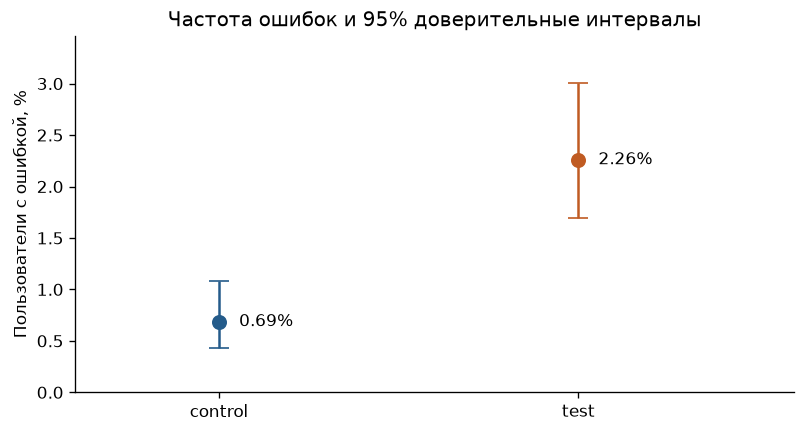

In [10]:
print(f'control: {int(summary.loc["control", "errors"])} / {len(control)} = {error_control:.3%}')
print(f'test: {int(summary.loc["test", "errors"])} / {len(test)} = {error_test:.3%}')
print(f'Разница test - control: {100 * error_diff:.3f} п.п.')
if error_ratio is not None:
    print(f'Отношение частот test / control: {error_ratio:.2f}')
print(f'p-value теста Фишера: {p_error:.3g}')


if guardrail_warning:
    print('Защитная метрика ухудшилась: ошибки чаще в test.')
else:
    print('Статистически значимого роста ошибок не обнаружено.')

# каждый интервал показывает неопределённость отдельной частоты ошибок
intervals = []
for group in GROUPS:
    k = int(summary.loc[group, 'errors'])
    n = int(summary.loc[group, 'users'])
    intervals.append(binomtest(k, n).proportion_ci(confidence_level=0.95, method='wilson'))

rates = np.array([error_control, error_test])
lower = np.array([interval.low for interval in intervals])
upper = np.array([interval.high for interval in intervals])
fig, ax = plt.subplots(figsize=(6.6, 3.5), layout='constrained')
for i, group in enumerate(GROUPS):
    ax.errorbar(
        i, 100 * rates[i],
        yerr=[[100 * (rates[i] - lower[i])], [100 * (upper[i] - rates[i])]],
        fmt='o', color=COLORS[i], markersize=8, capsize=6,
    )
    ax.annotate(f'{100 * rates[i]:.2f}%', (i, 100 * rates[i]), xytext=(12, 0),
                textcoords='offset points', va='center')
ax.set_xticks([0, 1], GROUPS)
ax.set_xlim(-0.4, 1.6)
ax.set_ylim(0, max(upper) * 100 * 1.15)
ax.set_ylabel('Пользователи с ошибкой, %')
ax.set_title('Частота ошибок и 95% доверительные интервалы')
plt.show()

в control 18 ошибок из 2625, в test 45 из 1992. частоты равны 0,686% и 2,259%. рост составляет 1,573 процентного пункта, p-value примерно 7,84 · 10⁻⁶. ошибки в test встречаются в 3,29 раза чаще. заданные вероятности 1% и 2% не означают, что в конечной случайной выборке отношение обязательно получится ровно 2.

## 6. Решение о валидности эксперимента

### Условие

Примите решение на основе проверок соотношения групп, активности и ошибок. Если есть хотя бы одно предупреждение, эксперимент невалиден. Вывод: «Остановить тест, исправить ошибки, перезапустить». Если всё в порядке, проведите стандартный анализ конверсии и сделайте вывод о значимости.

### Решение

`collect_warnings()` собирает причины, по которым эксперимент нельзя считать валидным. условие `if warnings` срабатывает, когда в списке есть хотя бы один элемент.

ветка `else` сравнивает конверсии тем же двусторонним тестом Фишера. она выполняется только при пустом списке предупреждений. отсутствие значимого различия конверсий в этой ветке не означало бы доказанное равенство вариантов.

порог 0,05 применяется отдельно к каждой проверке, как указано в задании. это не означает, что вероятность хотя бы одной ложной тревоги во всей процедуре равна 5%.

### Код

In [11]:
def collect_warnings(p_srm, p_activity, p_error, error_control, error_test, alpha=0.05):
    # каждое нарушение добавляет отдельную причину остановки
    warnings = []
    if p_srm < alpha:
        warnings.append('SRM обнаружен')
    if p_activity < alpha:
        warnings.append('Дисбаланс по pre_activity: возможен confounder')
    # уменьшение частоты ошибок не считается ухудшением защитной метрики
    if p_error < alpha and error_test > error_control:
        warnings.append('Защитная метрика ухудшилась: ошибки чаще в test')
    return warnings

warnings = collect_warnings(p_srm, p_activity, p_error, error_control, error_test, ALPHA)

### Проверка

In [12]:
diagnostics = pd.DataFrame({
    'Проверка': ['SRM', 'Баланс pre_activity', 'Рост ошибок'],
    'p-value': [p_srm, p_activity, p_error],
    'Предупреждение': [p_srm < ALPHA, p_activity < ALPHA, guardrail_warning],
})
diagnostics['p-value'] = diagnostics['p-value'].map('{:.3g}'.format)
display(diagnostics)

# непустого списка достаточно для остановки по правилу задания
if warnings:
    for warning in warnings:
        print(warning)
    print('Эксперимент невалиден.')
    print('Остановить тест, исправить ошибки, перезапустить.')
    print('Причинный вывод по конверсии не делается.')
else:
    print('По заданным проверкам нарушений не обнаружено.')
    # до первичной метрики доходим только при отсутствии всех предупреждений
    rate_control, rate_test, p_conversion = compare_binary(df, 'converted')
    print(f'Конверсия control: {rate_control:.2%}. test: {rate_test:.2%}')
    print(f'p-value для конверсии: {p_conversion:.3g}')
    if p_conversion < ALPHA:
        print('Различие конверсий статистически значимо.')
    else:
        print('Значимого различия конверсий не обнаружено.')

,Проверка,p-value,Предупреждение
0,SRM,1.21e-20,True
1,Баланс pre_activity,5.22e-07,True
2,Рост ошибок,7.84e-06,True


SRM обнаружен
Дисбаланс по pre_activity: возможен confounder
Защитная метрика ухудшилась: ошибки чаще в test
Эксперимент невалиден.
Остановить тест, исправить ошибки, перезапустить.
Причинный вывод по конверсии не делается.


обнаружены все три нарушения, поэтому сравнение конверсий в ветке `else` не выполняется. эксперимент нужно остановить. наблюдаемые +0,662 процентного пункта нельзя считать эффектом test.

перед перезапуском нужно назначать варианты независимо от активности с вероятностью 0,5 и сохранять назначение для повторных визитов. отдельно нужно найти причину ошибок загрузки в test и устранить её. после исправлений проверить распределение групп через A/A-тест, затем собрать новые данные. пользователей с ошибками нельзя удалять ради улучшения показателя.

## 7. Бонус. Подбор по исходной активности

### Условие

Предложите метод исправления одной из проблем, например коррекцию дисбаланса по `pre_activity`. Продемонстрируйте, как изменится вывод после исправления.

### Решение

для каждого значения `pre_activity` выбирается одинаковое число пользователей из control и test. если активность равна 3 у 100 пользователей control и у 80 пользователей test, останется по 80 из каждой группы. конкретные пользователи выбираются через `sample()` с фиксированным seed.

отбор не использует конверсию и ошибки. поэтому нельзя специально оставить тех, у кого результат выглядит лучше. исходная таблица `df` и CSV сохраняются, для подбора создаётся отдельная таблица `matched`.

после такого подбора распределения активности должны совпасть целиком, а не только по среднему. это проверяется таблицей `crosstab`: для каждого значения активности количества control и test должны быть равны.

подбор сокращает выборку и меняет состав пользователей. равенство размеров получено самим отбором, поэтому повторный SRM-тест на этой подвыборке не может подтвердить исправность исходной рандомизации. здесь проверяется, останется ли рост ошибок после выравнивания активности.

### Код

In [13]:
# подбираем пары только по признаку, измеренному до эксперимента
matched_parts = []
for activity, activity_group in df.groupby('pre_activity', sort=True):
    control_part = activity_group.loc[activity_group.variant == 'control']
    test_part = activity_group.loc[activity_group.variant == 'test']
    # берём минимум, чтобы при этой активности группы были одинакового размера
    n_keep = min(len(control_part), len(test_part))
    # без пользователей одной из групп пару составить нельзя
    if n_keep > 0:
        # фиксированный seed сохраняет тот же состав подвыборки при повторном запуске
        matched_parts.append(control_part.sample(n=n_keep, random_state=MY_SEED))
        matched_parts.append(test_part.sample(n=n_keep, random_state=MY_SEED))

matched = pd.concat(matched_parts, ignore_index=True).sort_values('user_id')

### Проверка

In [14]:
# для каждого уровня активности количества в двух группах должны совпасть.
matched_counts = pd.crosstab(matched.pre_activity, matched.variant).reindex(columns=GROUPS)
assert (matched_counts.control == matched_counts.test).all()
assert matched.user_id.is_unique
assert set(matched.user_id).issubset(set(df.user_id))

# исходная таблица остаётся целой, показатели сравниваются с подвыборкой
before_after = []
for stage, sample in [('До подбора', df), ('После подбора', matched)]:
    for group in GROUPS:
        part = sample.loc[sample.variant == group]
        before_after.append({
            'Выборка': stage,
            'Группа': group,
            'Пользователи': len(part),
            'Средняя активность': part.pre_activity.mean(),
            'Конверсия': part.converted.mean(),
            'Частота ошибок': part.error_flag.mean(),
        })

comparison_view = pd.DataFrame(before_after)
comparison_view['Средняя активность'] = comparison_view['Средняя активность'].round(3)
for column in ['Конверсия', 'Частота ошибок']:
    comparison_view[column] = comparison_view[column].map('{:.2%}'.format)
display(comparison_view)

matched_error_control, matched_error_test, p_error_matched = compare_binary(matched, 'error_flag')
print(f'Сохранено: {len(matched)} из {len(df)} пользователей ({len(matched) / len(df):.1%})')
print(f'Исключено: {len(df) - len(matched)} пользователей')
print(f'Частота ошибок после подбора: {matched_error_control:.3%} / {matched_error_test:.3%}')
print(f'p-value различия частот ошибок: {p_error_matched:.3g}')

if matched_error_test > matched_error_control and p_error_matched < ALPHA:
    print('После подбора значимый рост ошибок в test сохраняется.')
else:
    print('После подбора значимого роста ошибок не обнаружено. это не доказывает их устранение.')
print('Исходный эксперимент по-прежнему требует исправления и перезапуска.')

,Выборка,Группа,Пользователи,Средняя активность,Конверсия,Частота ошибок
0,До подбора,control,2625,8.605,4.61%,0.69%
1,До подбора,test,1992,10.292,5.27%,2.26%
2,После подбора,control,1898,9.136,5.16%,0.58%
3,После подбора,test,1898,9.136,5.22%,2.32%


Сохранено: 3796 из 4617 пользователей (82.2%)
Исключено: 821 пользователей
Частота ошибок после подбора: 0.580% / 2.318%
p-value различия частот ошибок: 7.54e-06
После подбора значимый рост ошибок в test сохраняется.
Исходный эксперимент по-прежнему требует исправления и перезапуска.


после подбора осталось по 1898 пользователей, всего 3796. исключено 821 наблюдение. распределения активности совпали, среднее равно 9,136 в обеих группах.

ошибки остались у 11 пользователей control и 44 пользователей test. частоты составляют 0,580% и 2,318%, p-value примерно 7,54 · 10⁻⁶. дисбаланс активности устранён в подвыборке, но рост ошибок сохранился. исходный эксперимент всё ещё требует исправления и перезапуска.